| **Inicio**         | **atrás 3**                          |
| ------------------ | ------------------------------------ |
| [🏠](../README.md) | [⏪](./5_3_Sistemas_lineales.ipynb) |

# 1. Primero: ¿qué es frecuencia?

Antes de Fourier hay que entender perfectamente la frecuencia.

Consideremos:

$x(t)=\sin(2\pi ft)$

donde:

$f=\text{frecuencia en Hz}$

Un Hertz significa:

$1\text{ Hz}=1\text{ ciclo/segundo}$

Por ejemplo:

$x(t)=\sin(2\pi 5t)$

realiza **5 ciclos por segundo**.

Su período es:

$\boxed{T=\frac{1}{f}}$

por lo que:

$T=\frac15=0.2s$

## Visualización en Python

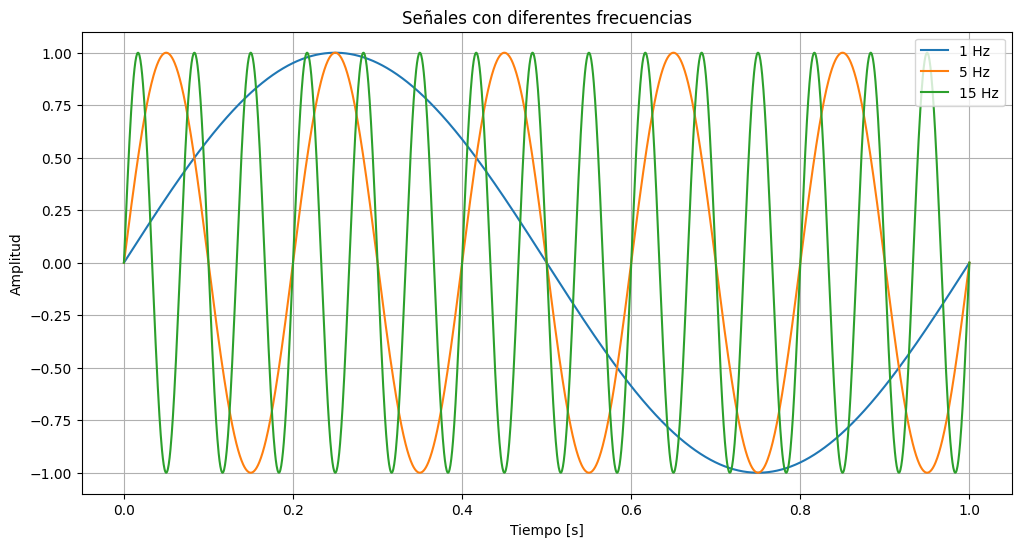

In [1]:
import numpy as np
import matplotlib.pyplot as plt

t = np.linspace(0, 1, 2000)

frequencies = [1, 5, 15]

plt.figure(figsize=(12, 6))

for f in frequencies:
    signal = np.sin(2 * np.pi * f * t)
    plt.plot(t, signal, label=f"{f} Hz")

plt.xlabel("Tiempo [s]")
plt.ylabel("Amplitud")
plt.title("Señales con diferentes frecuencias")
plt.legend()
plt.grid()

plt.show()

Observa:

$1\text{ Hz}\rightarrow1\text{ oscilación/s}$

$5\text{ Hz}\rightarrow5\text{ oscilaciones/s}$

$15\text{ Hz}\rightarrow15\text{ oscilaciones/s}$

Esta idea parece sencilla, pero será la variable fundamental del análisis de Fourier.

# 2. La idea central de Fourier

Supongamos que observas una señal complicada:

$x(t)$

como el sonido grabado por un micrófono.

En el dominio temporal ves algo como:

```text
amplitud
   ↑
   │  /\  /\/\_/\/\/\...
   │ /
───┼──────────────────→ tiempo
```

Es difícil saber qué contiene.

Fourier propone cambiar la pregunta.

En lugar de:

> ¿Cuál es la amplitud de la señal en cada instante?

preguntamos:

> ¿Qué frecuencias contiene esta señal y con qué intensidad?

Por ejemplo, una señal aparentemente complicada podría ser:

$x(t)
=$
$2\sin(2\pi 5t)
+
0.7\sin(2\pi 20t)
+
1.2\sin(2\pi 50t)$

Tenemos tres componentes:

$5\text{ Hz},\qquad20\text{ Hz},\qquad50\text{ Hz}$

En el tiempo parece complicada.

En frecuencia es extremadamente sencilla.

# 3. Primer experimento Fourier

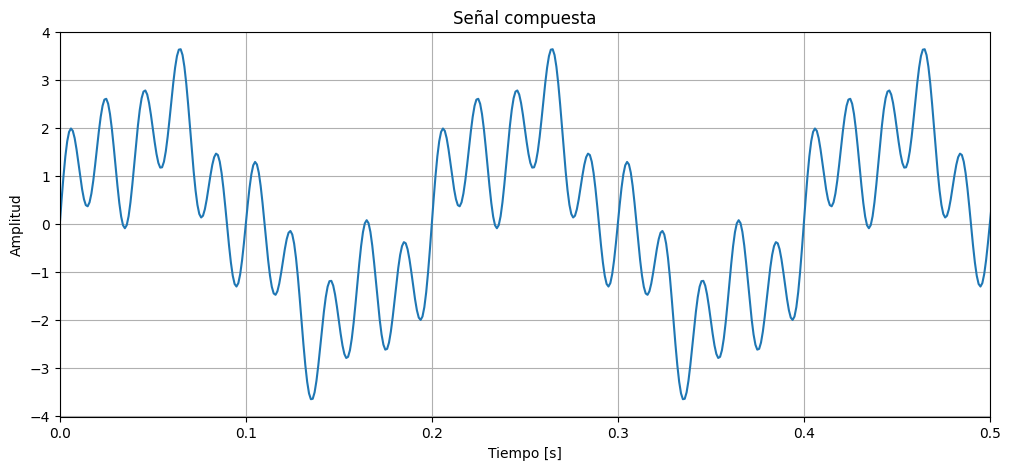

In [2]:
import numpy as np
import matplotlib.pyplot as plt

fs = 1000          # frecuencia de muestreo
duration = 2       # segundos

t = np.arange(0, duration, 1/fs)

signal = (
    2.0 * np.sin(2*np.pi*5*t)
    + 0.7 * np.sin(2*np.pi*20*t)
    + 1.2 * np.sin(2*np.pi*50*t)
)

plt.figure(figsize=(12, 5))

plt.plot(t, signal)

plt.xlim(0, 0.5)

plt.xlabel("Tiempo [s]")
plt.ylabel("Amplitud")
plt.title("Señal compuesta")

plt.grid()
plt.show()

Mirando únicamente este gráfico no resulta inmediatamente evidente que existen exactamente tres frecuencias.

Fourier nos permitirá descubrirlas.

# 4. Dominio temporal vs dominio frecuencial

Tenemos dos representaciones de exactamente la misma información.

### Dominio temporal


$x(t)$

nos dice:

$\boxed{\text{amplitud en función del tiempo}}$

### Dominio frecuencial

$X(f)$

nos dice:

$\boxed{\text{cantidad de cada frecuencia}}$

Conceptualmente:

$\boxed{
x(t)
\xrightarrow{\text{Fourier}}
X(f)
}$

y podemos regresar:

$\boxed{
X(f)
\xrightarrow{\text{Fourier inversa}}
x(t)
}$

No estamos creando información nueva.

Estamos cambiando de **representación**.

Esto es parecido a representar un vector utilizando otra base.

Y ahí aparece la primera conexión importante con álgebra lineal.

# 5. Fourier como cambio de base

Supongamos un vector:

$v=$
$\begin{bmatrix}
3\\
2
\end{bmatrix}$

Normalmente usamos los vectores base:

$e_1=$
$\begin{bmatrix}
1\\
0
\end{bmatrix},
\qquad
e_2=
\begin{bmatrix}
0\\
1
\end{bmatrix}$

Entonces:

$v=3e_1+2e_2$

Fourier hace algo conceptualmente similar con funciones.

En lugar de describir una señal directamente, la expresamos mediante una base formada por:

$\sin(nx),\qquad\cos(nx)$

Es decir:

$
\text{señal complicada}
=$
$\text{suma de ondas simples}
$

Esta interpretación será especialmente útil cuando llegues a métodos espectrales y FNO.

# 6. Fourier Series

Una **serie de Fourier** representa una función periódica mediante senos y cosenos.

La expresión general es:

$f(x)
=$
$\frac{a_0}{2}
+
\sum_{n=1}^{\infty}
\left[
a_n\cos(nx)
+
b_n\sin(nx)
\right]
$

Los coeficientes son:

$a_n=$
$\frac{1}{\pi}
\int_{-\pi}^{\pi}
f(x)\cos(nx)\,dx$

y

$b_n=$
$\frac{1}{\pi}
\int_{-\pi}^{\pi}
f(x)\sin(nx)\,dx$

Estos coeficientes responden:

> ¿Cuánto de la frecuencia $(n)$ existe dentro de la función?

# 7. Ejemplo clásico pero profundo: onda cuadrada

Consideremos:

$f(x)=$
$\begin{cases}
1 & 0<x<\pi\\
-1 & -\pi<x<0
\end{cases}$

Es una onda cuadrada.

Sorprendentemente puede construirse utilizando solamente senos:

$f(x)
=$
$\frac{4}{\pi}
\left(
\sin x
+
\frac13\sin3x
+
\frac15\sin5x
+
\frac17\sin7x
+\cdots
\right)
$

Esto significa que una forma aparentemente rectangular está compuesta por ondas sinusoidales.

# 8. Construyámosla gradualmente

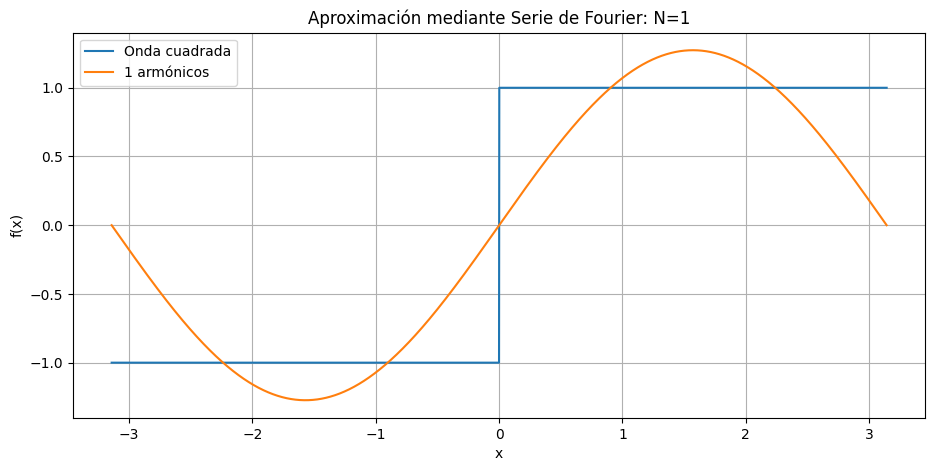

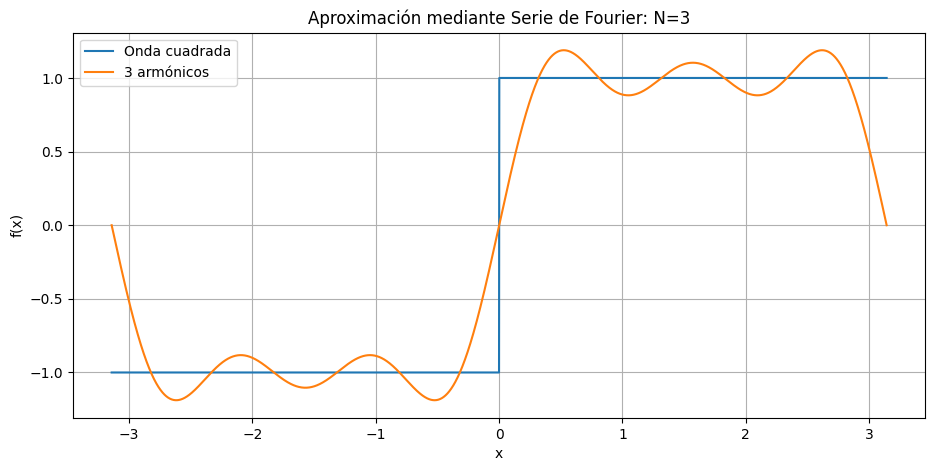

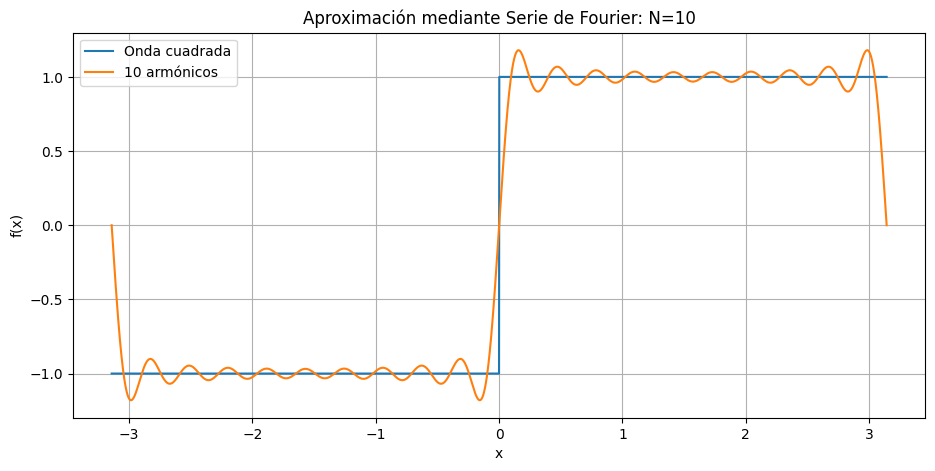

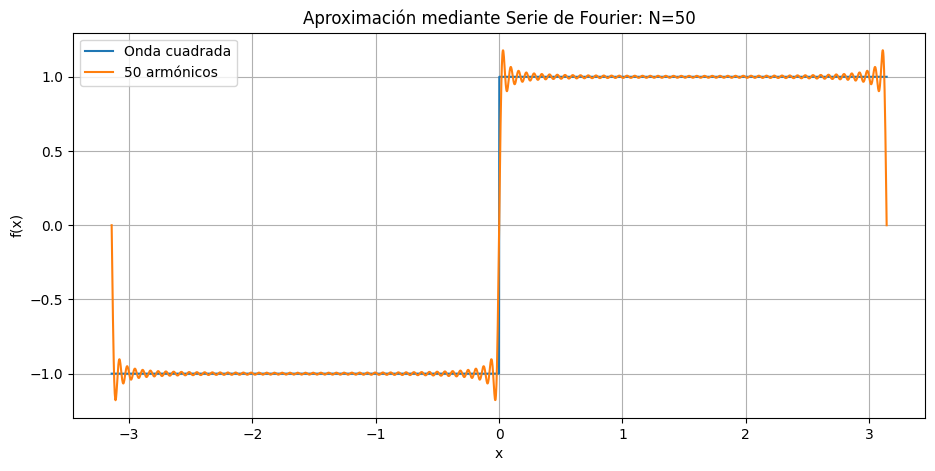

In [3]:
import numpy as np
import matplotlib.pyplot as plt

x = np.linspace(-np.pi, np.pi, 3000)

square_wave = np.sign(np.sin(x))

harmonics = [1, 3, 10, 50]

for N in harmonics:

    approximation = np.zeros_like(x)

    for k in range(N):

        n = 2*k + 1

        approximation += (
            4 / np.pi
            * np.sin(n*x)
            / n
        )

    plt.figure(figsize=(11, 5))

    plt.plot(
        x,
        square_wave,
        label="Onda cuadrada"
    )

    plt.plot(
        x,
        approximation,
        label=f"{N} armónicos"
    )

    plt.xlabel("x")
    plt.ylabel("f(x)")

    plt.title(
        f"Aproximación mediante Serie de Fourier: N={N}"
    )

    plt.legend()
    plt.grid()

    plt.show()

Mira qué ocurre al aumentar:

$N=1$

$N=3$

$N=10$

$N=50$

Cada nueva frecuencia añade detalle.

# 9. Fenómeno de Gibbs

Hay algo curioso cerca de las discontinuidades.

Incluso aumentando muchísimo $(N)$, aparecen pequeñas oscilaciones cerca del salto.

Eso se denomina:

$\boxed{\text{fenómeno de Gibbs}}$

No es simplemente un error de Python.

Es una propiedad matemática de aproximar discontinuidades mediante series de Fourier truncadas.

Puedes observarlo mejor:

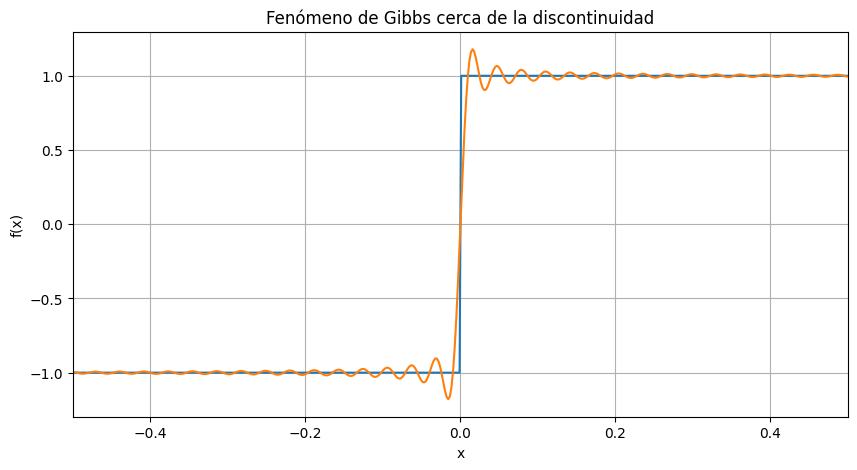

In [4]:
N = 100

approximation = np.zeros_like(x)

for k in range(N):

    n = 2*k + 1

    approximation += (
        4 / np.pi
        * np.sin(n*x)
        / n
    )

plt.figure(figsize=(10, 5))

plt.plot(x, square_wave)
plt.plot(x, approximation)

plt.xlim(-0.5, 0.5)

plt.xlabel("x")
plt.ylabel("f(x)")

plt.title("Fenómeno de Gibbs cerca de la discontinuidad")

plt.grid()
plt.show()

Esto tiene consecuencias en métodos numéricos espectrales.

# 10. De Fourier Series a Fourier Transform

La serie de Fourier funciona especialmente bien para funciones **periódicas**.

Pero ¿qué ocurre con una señal no periódica?

Por ejemplo, un pulso:

$x(t)=e^{-t^2}$

No se repite periódicamente.

Aquí aparece la **Transformada de Fourier**.

$X(f)
=$
$\int_{-\infty}^{\infty}
x(t)e^{-i2\pi ft}\,dt$

Y la transformada inversa:

$x(t)
=$
$\int_{-\infty}^{\infty}
X(f)e^{i2\pi ft}\,df$

Conceptualmente:

$x(t)
\longrightarrow
X(f)$

# 11. ¿Qué significa el exponencial complejo?

Tenemos:

$e^{i\theta}
=$
$\cos\theta+i\sin\theta$

Entonces:

$e^{-i2\pi ft}$

contiene simultáneamente senos y cosenos.

La transformada:

$X(f)
=$
$\int
x(t)e^{-i2\pi ft}dt$

puede interpretarse aproximadamente como:

> Comparar $x(t)$ con una onda de frecuencia $(f)$ y medir cuánto se parecen.

Si existe mucha componente de $(f=50)$ Hz:

$|X(50)|$

será grande.

Si prácticamente no existe una componente de 37 Hz:

$|X(37)|$

será pequeño.

# 12. Transformada de Fourier de nuestra señal

Volvamos a:

$x(t)
=$
$2\sin(2\pi5t)
+
0.7\sin(2\pi20t)
+
1.2\sin(2\pi50t)$

Utilizaremos FFT.

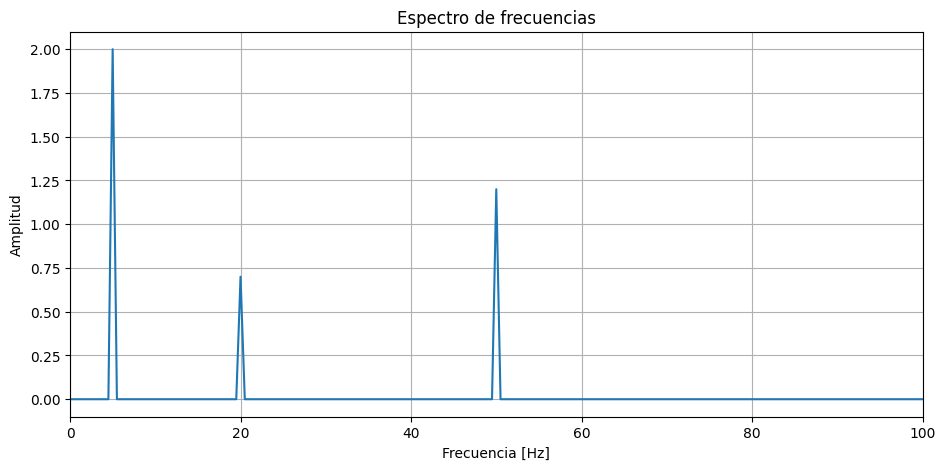

In [5]:
import numpy as np
import matplotlib.pyplot as plt

fs = 1000
duration = 2

t = np.arange(0, duration, 1/fs)

signal = (
    2.0 * np.sin(2*np.pi*5*t)
    + 0.7 * np.sin(2*np.pi*20*t)
    + 1.2 * np.sin(2*np.pi*50*t)
)

N = len(signal)

fft_values = np.fft.rfft(signal)

frequencies = np.fft.rfftfreq(
    N,
    d=1/fs
)

amplitude = 2 * np.abs(fft_values) / N

plt.figure(figsize=(11, 5))

plt.plot(
    frequencies,
    amplitude
)

plt.xlim(0, 100)

plt.xlabel("Frecuencia [Hz]")
plt.ylabel("Amplitud")

plt.title("Espectro de frecuencias")

plt.grid()
plt.show()

Deberías observar tres picos aproximadamente en:

$\boxed{5,\quad20,\quad50\text{ Hz}}$

con amplitudes:

$\boxed{2,\quad0.7,\quad1.2}$

Acabamos de descomponer la señal.

# 13. Ejemplo de vida real: audio

Un sonido es una variación de presión:

$p(t)$.

Un micrófono convierte esa variación en una señal eléctrica/digital.

Cuando escuchas una nota musical, normalmente no contiene una sola frecuencia.

Contiene:

$f_0$

y sus armónicos:

$2f_0,\quad3f_0,\quad4f_0,\ldots$

Por eso dos instrumentos tocando la misma nota pueden sonar diferentes.



Podemos simular un instrumento artificial.

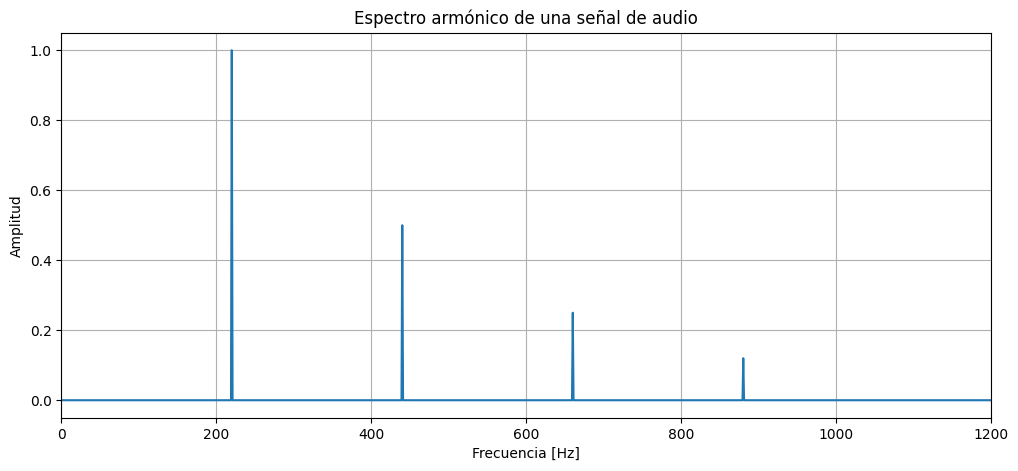

In [6]:
import numpy as np
import matplotlib.pyplot as plt

fs = 44100

duration = 1

t = np.arange(
    0,
    duration,
    1/fs
)

f0 = 220

signal = (
    1.0 * np.sin(2*np.pi*f0*t)
    + 0.5 * np.sin(2*np.pi*2*f0*t)
    + 0.25 * np.sin(2*np.pi*3*f0*t)
    + 0.12 * np.sin(2*np.pi*4*f0*t)
)

N = len(signal)

spectrum = np.fft.rfft(signal)

frequencies = np.fft.rfftfreq(
    N,
    1/fs
)

amplitude = 2*np.abs(spectrum)/N

plt.figure(figsize=(12, 5))

plt.plot(
    frequencies,
    amplitude
)

plt.xlim(0, 1200)

plt.xlabel("Frecuencia [Hz]")
plt.ylabel("Amplitud")

plt.title("Espectro armónico de una señal de audio")

plt.grid()
plt.show()

Encontrarás:

$220$

$440$

$660$

$880\text{ Hz}$.

# 14. ¿Qué es FFT?

Aquí suele haber una confusión importante.

**Fourier Transform** y **FFT** no son exactamente lo mismo.

Tenemos primero la Transformada de Fourier continua:

$\mathcal{F}\{x(t)\}$.

Cuando trabajamos con computadoras tenemos muestras:

$x_0,x_1,\ldots,x_{N-1}$.

Entonces utilizamos la **Discrete Fourier Transform (DFT)**:

$X_k
=$
$\sum_{n=0}^{N-1}
x_n
e^{-i2\pi kn/N}
$

para:

$k=0,\ldots,N-1$.

La FFT:

$\boxed{\text{Fast Fourier Transform}}$

es un algoritmo eficiente para calcular la DFT.

Es decir:

$\boxed{
\text{FFT no es otra transformada}
}$

sino:

$\boxed{
\text{FFT = algoritmo rápido para calcular la DFT}
}$

# 15. ¿Por qué la FFT fue tan importante?

Calcular directamente la DFT requiere aproximadamente:

$O(N^2)$

operaciones.

La FFT reduce esto aproximadamente a:

$\boxed{O(N\log N)}$

Imagina:

$N=1,000,000$.

DFT ingenua:

$N^2=10^{12}$.

FFT:

$N\log_2N
\approx
2\times10^7$.

La diferencia es enorme.

Por eso FFT aparece en:

- audio;
- telecomunicaciones;
- radar;
- astronomía;
- simulaciones físicas;
- imágenes;
- PDEs;
- SciML.

# 16. Sampling: un concepto crítico

Supongamos una señal:

$x(t)=\sin(2\pi100t)$.

Es una frecuencia de:

$100Hz$.

Pero una computadora no observa continuamente $(t)$.

Toma muestras:

$x(t_0),x(t_1),x(t_2),\ldots$

Si tomamos:

$f_s=1000Hz$,

tenemos 1000 muestras por segundo.

Según Nyquist:

$\boxed{
f_{\max}<\frac{f_s}{2}
}$

Por tanto:

$f_{\text{Nyquist}}=\frac{f_s}{2}$.

Si:

$f_s=1000Hz$,

podemos representar correctamente frecuencias menores a:

$500Hz$.

# 17. Aliasing

¿Qué ocurre si violamos Nyquist?

Supongamos una señal de:

$700Hz$

muestreada a:

$1000Hz$.

Como:

$700>500$,

la computadora puede interpretarla como otra frecuencia.

Eso es:

$\boxed{\text{aliasing}}$

Experimento:

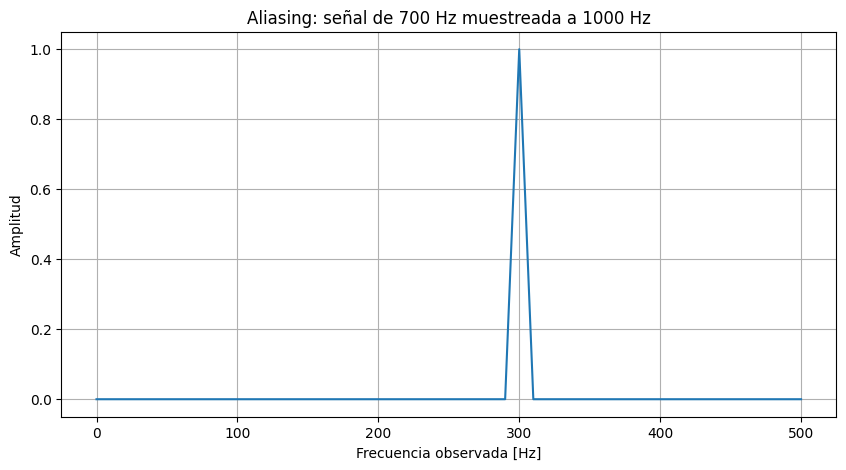

In [7]:
import numpy as np
import matplotlib.pyplot as plt

fs = 1000

f_signal = 700

duration = 0.1

t = np.arange(
    0,
    duration,
    1/fs
)

signal = np.sin(
    2*np.pi*f_signal*t
)

N = len(signal)

spectrum = np.fft.rfft(signal)

frequencies = np.fft.rfftfreq(
    N,
    1/fs
)

amplitude = 2*np.abs(spectrum)/N

plt.figure(figsize=(10, 5))

plt.plot(
    frequencies,
    amplitude
)

plt.xlabel("Frecuencia observada [Hz]")
plt.ylabel("Amplitud")

plt.title("Aliasing: señal de 700 Hz muestreada a 1000 Hz")

plt.grid()
plt.show()

Verás aproximadamente:

$300Hz$.

Porque:

$|700-1000|=300$.

El sistema digital ha confundido 700 Hz con 300 Hz.

Esto es importantísimo en datos científicos.

# 18. Ahora: convolución

La convolución parece inicialmente un tema separado.

En realidad está profundamente conectada con Fourier.

Para funciones continuas:

$
(f*g)(t)
=$
$\int_{-\infty}^{\infty}
f(\tau)
g(t-\tau)
d\tau
$

Para datos discretos:

$
y[n]
=$
$\sum_k
x[k]h[n-k]
$

Una forma intuitiva de pensarla es:

> deslizar un patrón sobre una señal y medir cómo interactúan.

# 19. Ejemplo cotidiano: suavizar datos ruidosos

Supongamos un sensor de temperatura.

La medición real contiene ruido:

$y(t)=T(t)+\epsilon(t)$.

Podemos utilizar un kernel:

$h=
\frac15
[1,1,1,1,1]$.

Esto calcula aproximadamente un promedio móvil.

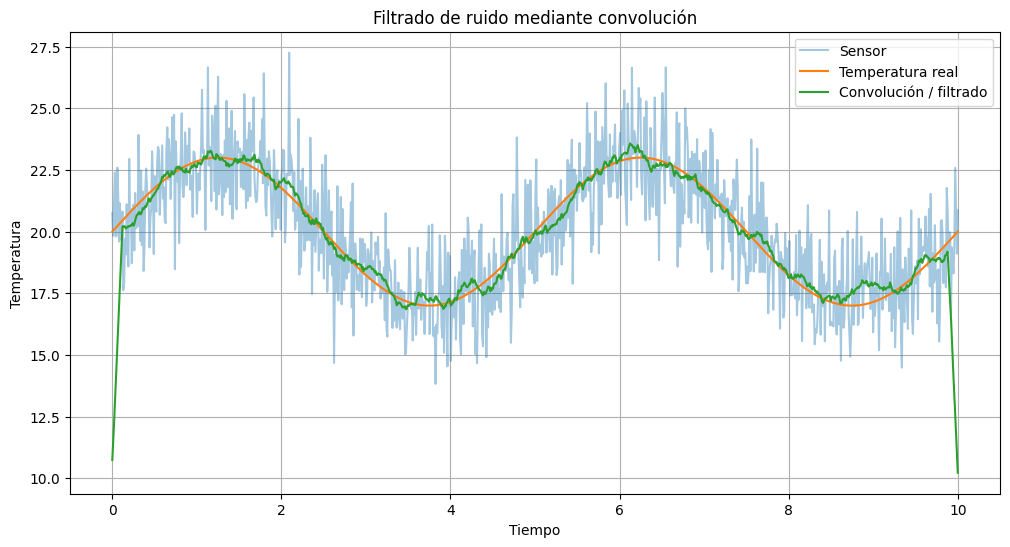

In [8]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)

t = np.linspace(
    0,
    10,
    1000
)

true_signal = (
    20
    + 3*np.sin(2*np.pi*0.2*t)
)

noise = np.random.normal(
    0,
    1.5,
    len(t)
)

measurement = (
    true_signal
    + noise
)

kernel_size = 25

kernel = (
    np.ones(kernel_size)
    / kernel_size
)

filtered = np.convolve(
    measurement,
    kernel,
    mode="same"
)

plt.figure(figsize=(12, 6))

plt.plot(
    t,
    measurement,
    alpha=0.4,
    label="Sensor"
)

plt.plot(
    t,
    true_signal,
    label="Temperatura real"
)

plt.plot(
    t,
    filtered,
    label="Convolución / filtrado"
)

plt.xlabel("Tiempo")
plt.ylabel("Temperatura")

plt.title("Filtrado de ruido mediante convolución")

plt.legend()
plt.grid()

plt.show()

Aquí la convolución funciona como filtro.

# 20. Convolución en imágenes

En imágenes tenemos una matriz:

$I(x,y)$.

Y un kernel, por ejemplo:

$K=
\begin{bmatrix}
-1&-1&-1\\
-1&8&-1\\
-1&-1&-1
\end{bmatrix}$.

Este kernel responde fuertemente a cambios rápidos de intensidad.

Es decir:

$\boxed{\text{detecta bordes}}$

Este es el origen matemático de la operación que hizo famosas a las **Convolutional Neural Networks**.

# 21. Ejemplo Python de convolución 2D

Generemos nosotros mismos una imagen sintética.

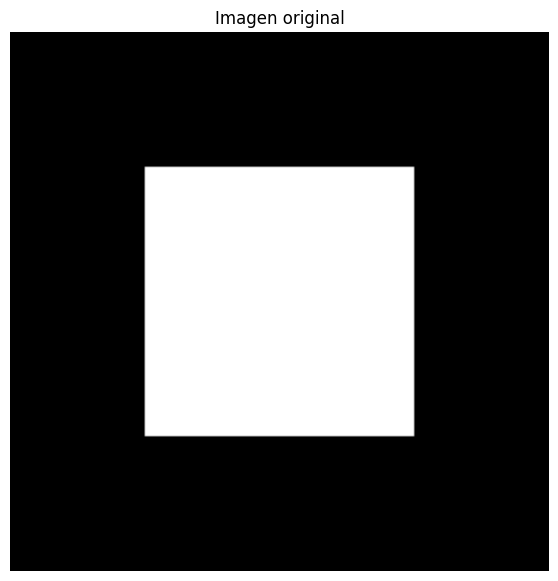

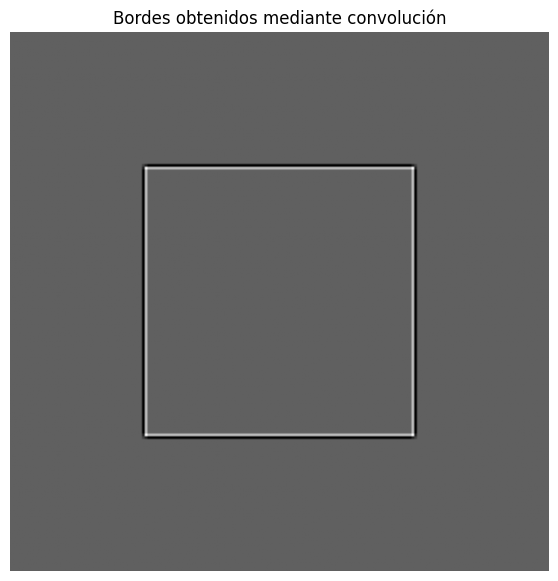

In [9]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import convolve2d

image = np.zeros((200, 200))

image[50:150, 50:150] = 1

kernel = np.array([
    [-1, -1, -1],
    [-1,  8, -1],
    [-1, -1, -1]
])

edges = convolve2d(
    image,
    kernel,
    mode="same",
    boundary="symm"
)

plt.figure(figsize=(7, 7))

plt.imshow(
    image,
    cmap="gray"
)

plt.title("Imagen original")
plt.axis("off")

plt.show()


plt.figure(figsize=(7, 7))

plt.imshow(
    edges,
    cmap="gray"
)

plt.title("Bordes obtenidos mediante convolución")
plt.axis("off")

plt.show()

La imagen original contiene un cuadrado.

Después de la convolución aparecen principalmente sus bordes.

# 22. La conexión extraordinaria: convolución y Fourier

Existe un resultado fundamental:

$\mathcal{F}(f*g)
=$
$\mathcal{F}(f)
\mathcal{F}(g)
$

Esto es el:

$\boxed{\text{Teorema de la Convolución}}$

Significa:

$\text{convolución en espacio/tiempo}$

se convierte en:

$\text{multiplicación en frecuencia}$.

Por tanto:

$f*g
=$
$\mathcal{F}^{-1}
\left[
\mathcal{F}(f)
\mathcal{F}(g)
\right]$.

Esta relación es extremadamente importante.

# 23. Hagamos convolución usando FFT

Podemos calcular una convolución de dos señales mediante:

```python
fft(signal)
fft(kernel)

multiplicación

ifft(...)
```

Por ejemplo:

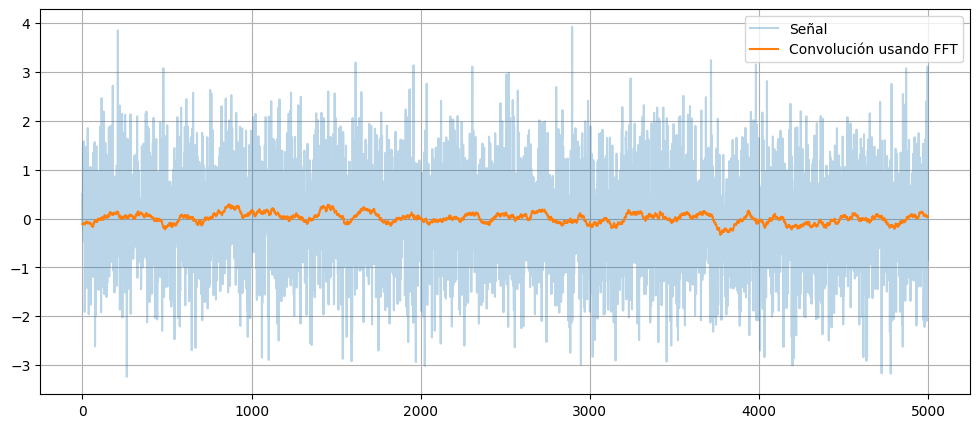

In [10]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import fftconvolve

np.random.seed(42)

N = 5000

signal = np.random.randn(N)

kernel_size = 100

kernel = (
    np.ones(kernel_size)
    / kernel_size
)

result = fftconvolve(
    signal,
    kernel,
    mode="same"
)

plt.figure(figsize=(12, 5))

plt.plot(
    signal,
    alpha=0.3,
    label="Señal"
)

plt.plot(
    result,
    label="Convolución usando FFT"
)

plt.legend()
plt.grid()

plt.show()

Para señales grandes esto puede ser muchísimo más eficiente que realizar directamente la convolución.

# 24. Ejemplo difícil: eliminar ruido mediante Fourier

Ahora hagamos algo más cercano a un problema científico.

Tenemos:

$x(t)
=$
$\sin(2\pi10t)
+
0.5\sin(2\pi30t)
+
\epsilon(t)$.

Queremos recuperar la señal.

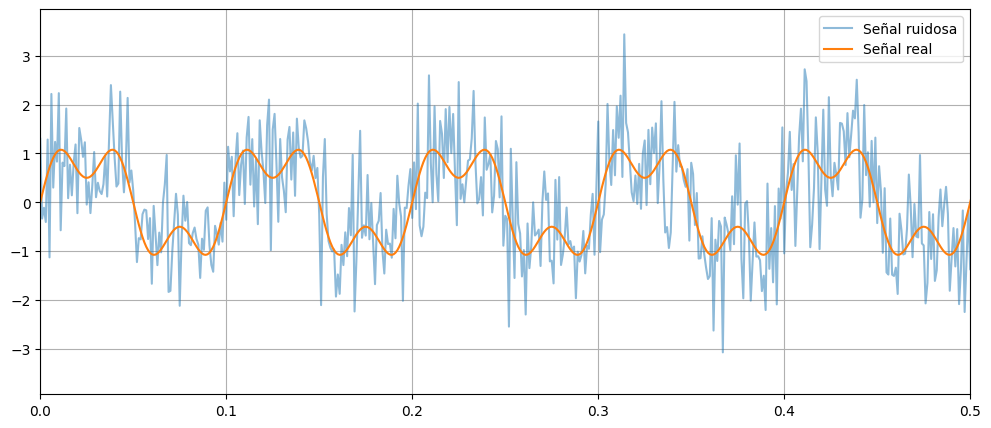

In [11]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(1)

fs = 1000
duration = 2

t = np.arange(
    0,
    duration,
    1/fs
)

clean_signal = (
    np.sin(2*np.pi*10*t)
    + 0.5*np.sin(2*np.pi*30*t)
)

noise = (
    0.8
    * np.random.randn(len(t))
)

noisy_signal = (
    clean_signal
    + noise
)

plt.figure(figsize=(12, 5))

plt.plot(
    t,
    noisy_signal,
    alpha=0.5,
    label="Señal ruidosa"
)

plt.plot(
    t,
    clean_signal,
    label="Señal real"
)

plt.xlim(0, 0.5)

plt.legend()
plt.grid()

plt.show()

Ahora Fourier.

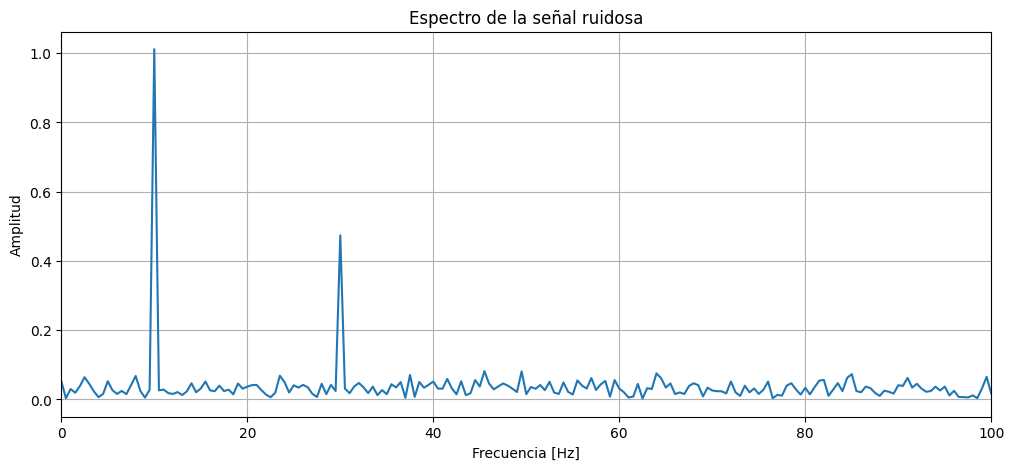

In [12]:
N = len(noisy_signal)

spectrum = np.fft.rfft(
    noisy_signal
)

frequencies = np.fft.rfftfreq(
    N,
    1/fs
)

amplitude = (
    2*np.abs(spectrum)/N
)

plt.figure(figsize=(12, 5))

plt.plot(
    frequencies,
    amplitude
)

plt.xlim(0, 100)

plt.xlabel("Frecuencia [Hz]")
plt.ylabel("Amplitud")

plt.title("Espectro de la señal ruidosa")

plt.grid()
plt.show()

Aunque la señal temporal parece caótica, deberías encontrar actividad importante cerca de:

$10Hz$

y

$30Hz$.

# 25. Filtrado frecuencial

Supongamos que sabemos que nuestra física relevante está por debajo de:

$50Hz$.

Eliminamos frecuencias superiores.

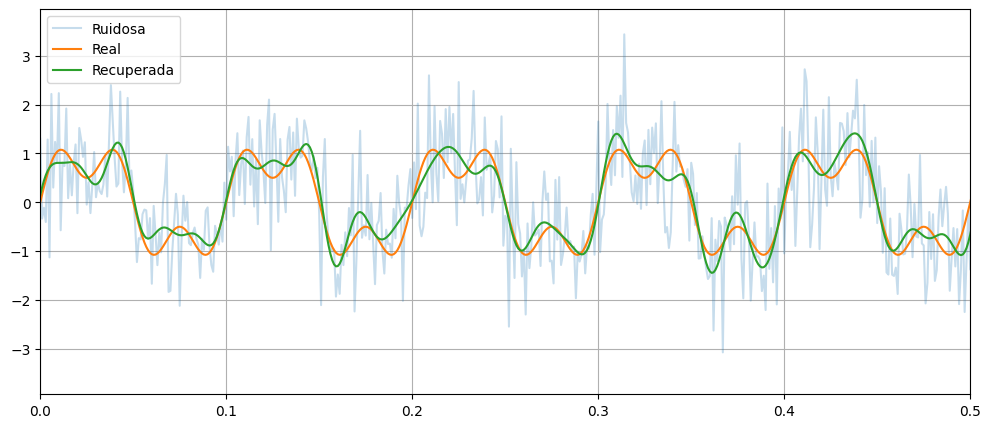

In [13]:
filtered_spectrum = spectrum.copy()

filtered_spectrum[
    frequencies > 50
] = 0

recovered_signal = np.fft.irfft(
    filtered_spectrum,
    n=N
)

plt.figure(figsize=(12, 5))

plt.plot(
    t,
    noisy_signal,
    alpha=0.25,
    label="Ruidosa"
)

plt.plot(
    t,
    clean_signal,
    label="Real"
)

plt.plot(
    t,
    recovered_signal,
    label="Recuperada"
)

plt.xlim(0, 0.5)

plt.legend()
plt.grid()

plt.show()

Acabas de realizar:

$\boxed{
\text{señal}
\rightarrow
FFT
\rightarrow
\text{filtrado}
\rightarrow
IFFT
\rightarrow
\text{señal reconstruida}
}$

Esta estrategia aparece muchísimo en ciencia e ingeniería.

# 26. Ejemplo más difícil: vibraciones de una máquina


Imagina un motor industrial.



Un acelerómetro mide vibraciones.

Supongamos:

$x(t)
=$
$A_1\sin(2\pi f_1t)
+
A_2\sin(2\pi f_2t)
+
A_3\sin(2\pi f_3t)
+
\epsilon$.

El motor gira normalmente a:

$30Hz$.

Pero un rodamiento defectuoso introduce:

$120Hz$.

Simulemos:

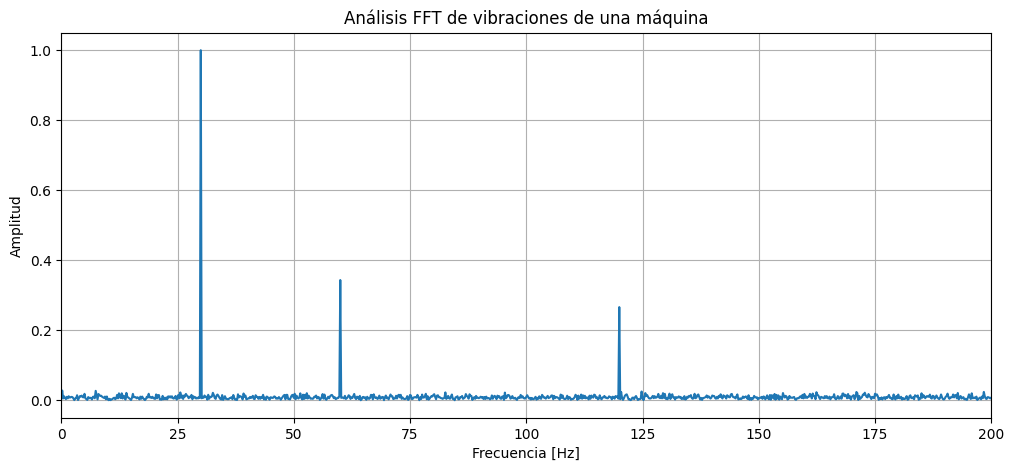

In [14]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(10)

fs = 2000
duration = 5

t = np.arange(
    0,
    duration,
    1/fs
)

rotation = (
    1.0
    * np.sin(2*np.pi*30*t)
)

harmonic = (
    0.35
    * np.sin(2*np.pi*60*t)
)

bearing_fault = (
    0.25
    * np.sin(2*np.pi*120*t)
)

noise = (
    0.5
    * np.random.randn(len(t))
)

measurement = (
    rotation
    + harmonic
    + bearing_fault
    + noise
)

N = len(measurement)

spectrum = np.fft.rfft(
    measurement
)

frequencies = np.fft.rfftfreq(
    N,
    1/fs
)

amplitude = (
    2*np.abs(spectrum)/N
)

plt.figure(figsize=(12, 5))

plt.plot(
    frequencies,
    amplitude
)

plt.xlim(0, 200)

plt.xlabel("Frecuencia [Hz]")
plt.ylabel("Amplitud")

plt.title(
    "Análisis FFT de vibraciones de una máquina"
)

plt.grid()
plt.show()

Ahora aparecen aproximadamente:

$30Hz$

rotación principal;

$60Hz$

armónico;

$120Hz$

posible componente asociada al fallo.

Esto es un ejemplo realista de **condition monitoring / predictive maintenance**.

# 27. Ejemplo aún más difícil: señal cuya frecuencia cambia

Hay una limitación importante de la transformada de Fourier tradicional.

Supongamos:

$x(t)=\sin(2\pi f(t)t)$

donde la frecuencia cambia con el tiempo.

Por ejemplo, un *chirp*:

$20Hz\rightarrow200Hz$.

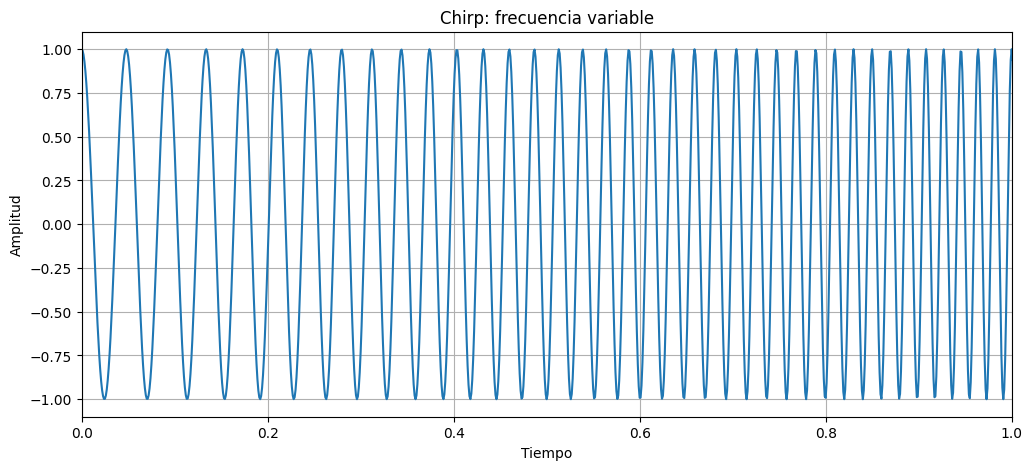

In [15]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import chirp

fs = 1000

t = np.arange(
    0,
    5,
    1/fs
)

signal = chirp(
    t,
    f0=20,
    f1=200,
    t1=5,
    method="linear"
)

plt.figure(figsize=(12, 5))

plt.plot(t, signal)

plt.xlim(0, 1)

plt.xlabel("Tiempo")
plt.ylabel("Amplitud")

plt.title("Chirp: frecuencia variable")

plt.grid()
plt.show()

La FFT nos dice qué frecuencias existen, pero pierde parcialmente una información:

$\boxed{\text{cuándo aparece cada frecuencia}}$

Ahí aparecen herramientas posteriores como:

- Short-Time Fourier Transform (STFT);
- espectrogramas;
- wavelets.

# 28. Espectrograma

Podemos representar:

$\boxed{
\text{tiempo}
\times
\text{frecuencia}
\times
\text{energía}
}$

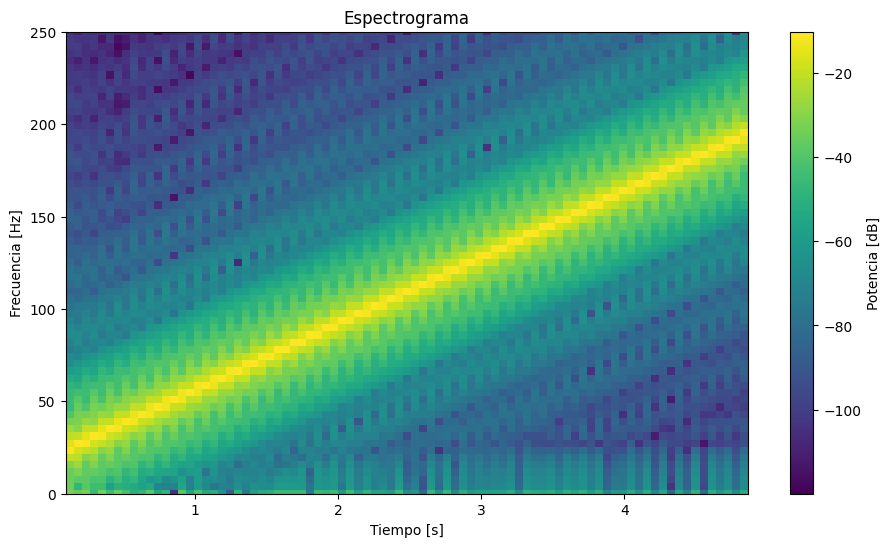

In [16]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import spectrogram

frequencies, times, Sxx = spectrogram(
    signal,
    fs=fs,
    nperseg=256,
    noverlap=200
)

plt.figure(figsize=(11, 6))

plt.pcolormesh(
    times,
    frequencies,
    10*np.log10(Sxx + 1e-12),
    shading="auto"
)

plt.xlabel("Tiempo [s]")
plt.ylabel("Frecuencia [Hz]")

plt.title("Espectrograma")

plt.ylim(0, 250)

plt.colorbar(
    label="Potencia [dB]"
)

plt.show()

Ahora puedes observar cómo la frecuencia aumenta progresivamente.

Esto conecta Fourier con análisis moderno de señales.

# 29. Fourier + ecuaciones diferenciales

Ahora viene una de las conexiones más importantes para SciML.

Consideremos la ecuación del calor:

$\frac{\partial u}{\partial t}
=$
$\alpha
\frac{\partial^2u}{\partial x^2}$

Esto es una **PDE**.

Supongamos una solución en modos Fourier:

$u(x,t)
=$
$\sum_k
\hat u_k(t)e^{ikx}$.

Como:

$\frac{\partial^2}{\partial x^2}
e^{ikx}
=$
$-k^2e^{ikx}$,

la derivada espacial se transforma en:

$\boxed{
\frac{\partial^2}{\partial x^2}
\longrightarrow
-k^2
}
$

Entonces:

$\frac{\partial u}{\partial t}
=$
$\alpha u_{xx}$

se transforma aproximadamente en:

$
\frac{d\hat u_k}{dt}
=$
$-\alpha k^2\hat u_k
$

¡Convertimos una PDE en muchas ODE independientes!

Y sabemos resolver:

$\frac{d\hat u_k}{dt}
=$
$-\alpha k^2\hat u_k$.


La solución es:

$
\hat u_k(t)
=$
$\hat u_k(0)
e^{-\alpha k^2t}$

Esta es una de las razones profundas por las que Fourier es tan importante en física matemática y SciML.

# 30. Resolver la ecuación del calor con FFT

Hagamos un solver espectral.

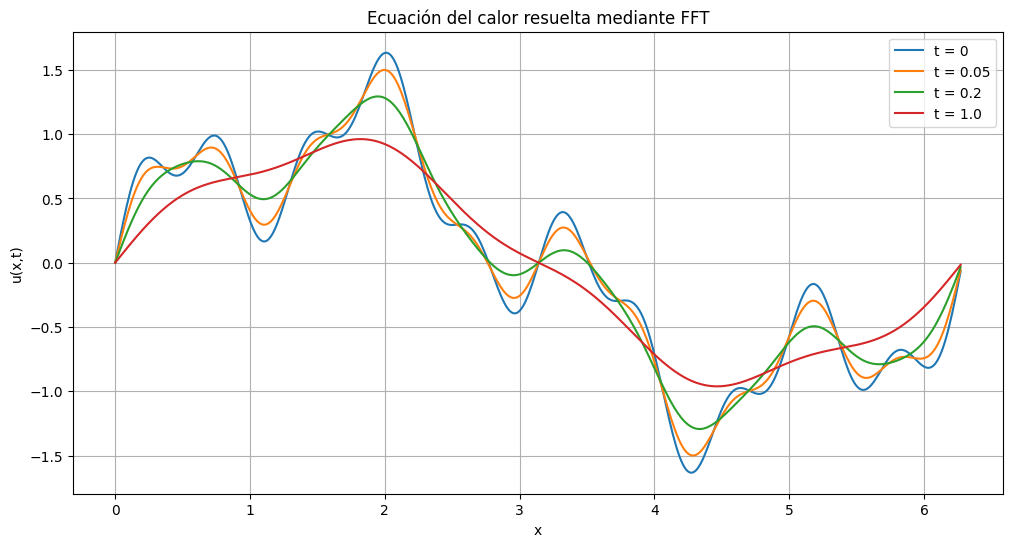

In [17]:
import numpy as np
import matplotlib.pyplot as plt

# Dominio espacial
L = 2*np.pi

N = 512

x = np.linspace(
    0,
    L,
    N,
    endpoint=False
)

dx = L / N

# Difusividad
alpha = 0.1

# Condición inicial complicada
u0 = (
    np.sin(x)
    + 0.5*np.sin(4*x)
    + 0.25*np.sin(10*x)
)

# Transformada inicial
u_hat0 = np.fft.fft(u0)

# Números de onda
k = (
    2*np.pi
    * np.fft.fftfreq(N, d=dx)
)

times = [
    0,
    0.05,
    0.2,
    1.0
]

plt.figure(figsize=(12, 6))

for t in times:

    u_hat = (
        u_hat0
        * np.exp(
            -alpha
            * k**2
            * t
        )
    )

    u = np.real(
        np.fft.ifft(u_hat)
    )

    plt.plot(
        x,
        u,
        label=f"t = {t}"
    )

plt.xlabel("x")
plt.ylabel("u(x,t)")

plt.title(
    "Ecuación del calor resuelta mediante FFT"
)

plt.legend()
plt.grid()

plt.show()

Este ejemplo es especialmente importante para tu ruta de SciML.

Observa que las frecuencias altas desaparecen más rápido porque:

$e^{-\alpha k^2t}$.

Si $(k)$ es grande:

$k^2\gg1$

y entonces:

$e^{-\alpha k^2t}
\rightarrow0$

muy rápidamente.

Físicamente significa:

> Las variaciones espaciales muy rápidas de temperatura se suavizan antes que las variaciones grandes.

# 31. Visualización 2D de la PDE

Podemos construir toda la solución:

$u(x,t)$.

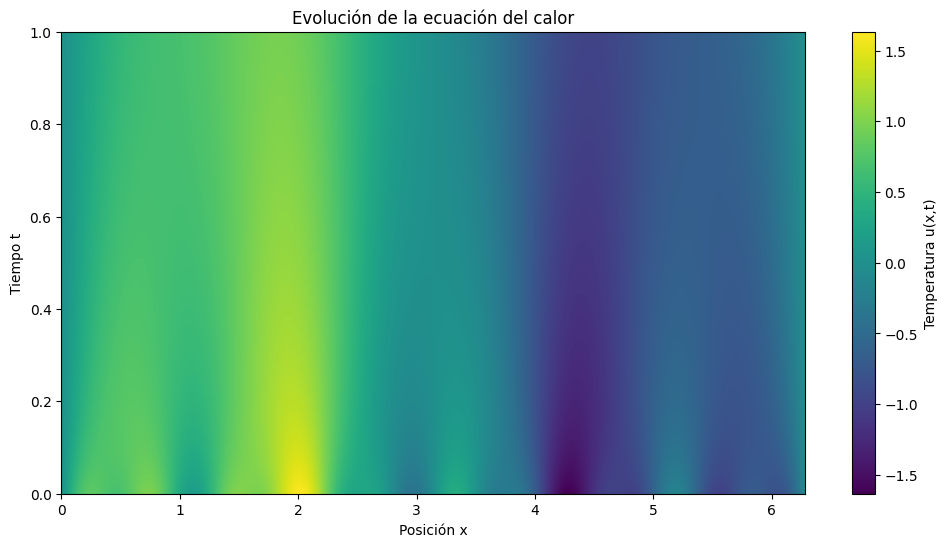

In [18]:
import numpy as np
import matplotlib.pyplot as plt

time_values = np.linspace(
    0,
    1,
    300
)

U = np.zeros(
    (len(time_values), N)
)

for i, t in enumerate(time_values):

    u_hat = (
        u_hat0
        * np.exp(
            -alpha
            * k**2
            * t
        )
    )

    U[i] = np.real(
        np.fft.ifft(u_hat)
    )

plt.figure(figsize=(12, 6))

plt.imshow(
    U,
    aspect="auto",
    origin="lower",
    extent=[
        0,
        L,
        0,
        1
    ]
)

plt.xlabel("Posición x")
plt.ylabel("Tiempo t")

plt.title(
    "Evolución de la ecuación del calor"
)

plt.colorbar(
    label="Temperatura u(x,t)"
)

plt.show()

Ahora puedes observar simultáneamente:

$x$

$t$

y

$u(x,t)$.

# 32. La conexión directa con Scientific Machine Learning

Aquí es donde todo lo anterior empieza a juntarse.

Supongamos que tenemos una PDE:

$\frac{\partial u}{\partial t}
=$
$F(u)$.

Podemos aprender un operador:

$\boxed{
\mathcal{G}:
u(x,0)
\rightarrow
u(x,t)
}$

Es decir, darle al modelo una condición inicial y pedirle que prediga la solución futura completa.

Aquí aparecen los **Neural Operators**.

Una arquitectura especialmente relevante es:

$\boxed{\text{Fourier Neural Operator}}$

La idea simplificada de una capa es:

$v_{l+1}(x)
=$
$\sigma
\left(
Wv_l(x)
+
\mathcal{F}^{-1}
\left(
R_\theta(k)
\mathcal{F}(v_l)
\right)
\right)$.

Mira atentamente lo que está ocurriendo:

$v(x)$

↓

$\boxed{\text{FFT}}$

↓

$\hat v(k)$

↓

se modifican ciertos modos Fourier

$R_\theta(k)\hat v(k)$

↓

$\boxed{\text{IFFT}}$

↓

$v_{\text{nuevo}}(x)$.

Por eso entender FFT solamente como “un algoritmo para encontrar frecuencias de audio” sería quedarse muy corto para SciML.

# 33. El mapa mental que deberías conservar

Piensa en estos conceptos así:

$\boxed{\text{Frecuencia}}$

describe la rapidez de las oscilaciones.

↓

$\boxed{\text{Serie de Fourier}}$

descompone funciones periódicas:

$f(x)
=$
$\sum
\text{senos/cosenos}$.

↓

$\boxed{\text{Transformada de Fourier}}$

transforma:

$x(t)
\rightarrow
X(f)$.

↓

$\boxed{\text{DFT}}$

hace Fourier sobre datos discretos.

↓

$\boxed{\text{FFT}}$

calcula eficientemente la DFT.

↓

$\boxed{\text{Convolución}}$

combina una señal con un kernel.

↓

Teorema de convolución:

$\boxed{
f*g
\leftrightarrow
F(f)F(g)
}$

↓

Las derivadas también se simplifican:


$\boxed{
\frac{d}{dx}
\leftrightarrow
ik
}$


$\boxed{
\frac{d^2}{dx^2}
\leftrightarrow
-k^2
}$

↓

por lo que Fourier es potentísimo para:

$\boxed{\text{PDEs}}$

↓

y finalmente:


$
\text{métodos espectrales}
+
\text{PDE}
+
\text{ML}
=$
$\text{SciML}
$

| **Inicio**         | **atrás 3**                          |
| ------------------ | ------------------------------------ |
| [🏠](../README.md) | [⏪](./5_3_Sistemas_lineales.ipynb) |